# AQUA-STRAT — Objective 2b: Floating Debris Index (FDI), final integrated version

Complete, self-contained pipeline: search Sentinel-2 tiles → compute FDI at native
resolution (no quality loss, no `reproject()` slowdown) → aggregate onto your
existing grid → **validate against your LSTM-predicted plastic density**. Crash-safe
and resumable throughout (Drive-persisted, incremental).

**Why this exists**: your CNN detects plastic from close-range photos; this adds a
wide-area satellite screening layer (FDI) on top, and Section 9 checks whether the
two agree — genuinely integrating this into AQUA-STRAT rather than a standalone demo.

Source: **Earth Search v1** (Element 84), a free, login-free public STAC/COG archive
on AWS.
- STAC API: `https://earth-search.aws.element84.com/v1`
- Data bucket: `s3://sentinel-cogs` (public, no-sign-request)


## 1. Setup

In [1]:
!pip install pystac-client rasterio tqdm scipy --quiet


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 41.8/41.8 kB 1.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 117.3/117.3 kB 7.9 MB/s eta 0:00:00


In [2]:
import os
import time
import warnings
import gc
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import rasterio
from rasterio.enums import Resampling
from rasterio.warp import transform_bounds
from pystac_client import Client
from tqdm.auto import tqdm
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize

os.environ["GDAL_DISABLE_READDIR_ON_OPEN"] = "EMPTY_DIR"
os.environ["CPL_VSIL_CURL_ALLOWED_EXTENSIONS"] = ".tif"
os.environ["GDAL_HTTP_MULTIRANGE"] = "YES"
os.environ["AWS_NO_SIGN_REQUEST"] = "YES"
os.environ["GDAL_HTTP_TIMEOUT"] = "20"
os.environ["GDAL_HTTP_CONNECTTIMEOUT"] = "10"
os.environ["GDAL_HTTP_MAX_RETRY"] = "2"
os.environ["GDAL_HTTP_RETRY_DELAY"] = "1"
# RAM-leak fix: VSI_CACHE + unbounded GDAL block cache accumulate across every
# remote file opened in the session. This is what crashed the runtime after
# AS+BOB (~40 tiles) succeeded and IO started -- not something IO-specific.
os.environ["VSI_CACHE"] = "FALSE"
os.environ["GDAL_CACHEMAX"] = "128"  # MB, hard ceiling on GDAL's internal block cache

STAC_URL = "https://earth-search.aws.element84.com/v1"
catalog = Client.open(STAC_URL)
print("Connected to:", STAC_URL)


Connected to: https://earth-search.aws.element84.com/v1


## 2. Mount Drive (for OUTPUT persistence only — not your 47.5GB input data)

Outputs here are tiny: one small GeoTIFF per tile (a few MB) plus a summary CSV.
Mounting Drive costs nothing extra and means a crash no longer wipes your progress —
`/content` gets wiped on a crash/restart, `/content/drive` does not.


In [3]:
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


## 3. Region bounding boxes + settings

In [4]:
REGION_BBOX = {
    "AS":  {"lat_min": 8.0,   "lat_max": 24.0, "lon_min": 66.0, "lon_max": 76.0},
    "BOB": {"lat_min": 6.0,   "lat_max": 22.0, "lon_min": 80.0, "lon_max": 93.0},
    "IO":  {"lat_min": -20.0, "lat_max": 25.0, "lon_min": 40.0, "lon_max": 100.0},
}

MAX_ITEMS_PER_REGION = 20
DATE_RANGE = "2024-06-01/2025-12-31"
MAX_CLOUD_COVER = 20
# No target-resolution knob anymore — we always use each band's true native
# resolution (20m), with only the unavoidable 10m->20m B08 alignment.


## 4. Search for the least-cloudy tiles per region

**Note on IO specifically**: its bounding box is far larger than AS/BOB (60°×45° vs
~10°×15°), so without bounding pagination this search can page through thousands of
granules before ever getting to sort/slice — `max_items` below fixes that. A hard
timeout is also added so a genuine network stall gets reported instead of hanging.


In [5]:
from concurrent.futures import ThreadPoolExecutor, TimeoutError as FutureTimeoutError

SEARCH_TIMEOUT_S = 60  # hard ceiling per region's search call

def search_region(region, bbox_dict, max_items=20):
    bbox = [bbox_dict["lon_min"], bbox_dict["lat_min"], bbox_dict["lon_max"], bbox_dict["lat_max"]]
    # max_items bounds TOTAL pagination -- without this, list(search.items()) pages
    # through every matching granule in the date range/bbox before Python ever
    # slices it down. For a huge bbox like IO, that's the actual hang -- not a
    # network stall. Pulling a modest pool (15x what we need) and sorting within
    # that pool is fast and still gives a good least-cloudy selection.
    search = catalog.search(
        collections=["sentinel-2-l2a"],
        bbox=bbox,
        datetime=DATE_RANGE,
        query={"eo:cloud_cover": {"lt": MAX_CLOUD_COVER}},
        max_items=max_items * 15,
        limit=100,
    )
    items = list(search.items())
    items.sort(key=lambda it: it.properties.get("eo:cloud_cover", 100))
    return items[:max_items]


region_items = {}
for region, bbox_dict in REGION_BBOX.items():
    print(f"Searching {region} ...", flush=True)
    with ThreadPoolExecutor(max_workers=1) as ex:
        future = ex.submit(search_region, region, bbox_dict, MAX_ITEMS_PER_REGION)
        try:
            items = future.result(timeout=SEARCH_TIMEOUT_S)
        except FutureTimeoutError:
            print(f"  [TIMEOUT] {region} search exceeded {SEARCH_TIMEOUT_S}s — skipped. "
                  f"Narrow DATE_RANGE or lower MAX_CLOUD_COVER and re-run this cell.")
            items = []

    region_items[region] = items
    ccs = [i.properties.get("eo:cloud_cover", 0) for i in items]
    if items:
        print(f"{region}: {len(items)} tiles selected (cloud cover {min(ccs):.1f}-{max(ccs):.1f}%)")
    else:
        print(f"{region}: 0 tiles found — widen DATE_RANGE or MAX_CLOUD_COVER, or search timed out above")


Searching AS ...
AS: 20 tiles selected (cloud cover 0.0-0.0%)
Searching BOB ...
BOB: 20 tiles selected (cloud cover 0.0-0.0%)
Searching IO ...
IO: 20 tiles selected (cloud cover 0.0-0.0%)


## 5. FDI computation — native 20m grid, no `reproject()`

- B06 (Red-Edge, native 20m) → read directly, full native resolution, zero decimation
- B11 (SWIR, native 20m) → read directly, full native resolution, zero decimation
- B08 (NIR, native 10m) → read with `out_shape` at half dimensions (2× decimation,
  average resampling) to align to the *same* 20m grid as B06/B11 — this exact step
  is unavoidable in the algorithm itself, not an extra quality cut
- All three now share the same bounds + shape by construction (same MGRS tile), so
  no warping/reprojection is needed to combine them.


In [6]:
LAMBDA_RE, LAMBDA_NIR, LAMBDA_SWIR = 705.0, 833.0, 1610.0

def get_band_urls(item):
    assets = item.assets
    return {
        "b06": assets["rededge1"].href,
        "b08": assets["nir"].href,
        "b11": assets["swir16"].href,
    }


def read_native(url):
    """Full native-resolution read, no decimation."""
    with rasterio.open(url) as src:
        data = src.read(1).astype(np.float32)
        return data, src.transform, src.crs, src.bounds, (src.height, src.width)


def read_matched(url, target_shape):
    """Decimated read to an exact target (h, w), used only for the 10m B08 band."""
    with rasterio.open(url) as src:
        data = src.read(
            1,
            out_shape=target_shape,
            resampling=Resampling.average,
        ).astype(np.float32)
        return data


def compute_fdi_for_item(item):
    urls = get_band_urls(item)

    # B06 defines the reference native-20m grid
    b06, transform, crs, bounds, shape = read_native(urls["b06"])
    # B11 is also native 20m and covers the same tile bounds -> same shape, direct read
    b11, _, _, _, b11_shape = read_native(urls["b11"])
    # B08 is native 10m -> the only necessary decimation, matched to B06's exact shape
    b08 = read_matched(urls["b08"], target_shape=shape)

    # Defensive: if B11's native shape differs by a pixel or two from B06 (rare,
    # tile edge rounding), trim to the common minimum rather than warping.
    h = min(shape[0], b11_shape[0], b08.shape[0])
    w = min(shape[1], b11_shape[1], b08.shape[1])
    b06, b11, b08 = b06[:h, :w], b11[:h, :w], b08[:h, :w]

    scale = 10000.0
    r_re, r_nir, r_swir = b06 / scale, b08 / scale, b11 / scale
    r_nir_prime = r_re + (r_swir - r_re) * ((LAMBDA_NIR - LAMBDA_RE) / (LAMBDA_SWIR - LAMBDA_RE)) * 10.0
    fdi = r_nir - r_nir_prime

    profile = {
        "height": h, "width": w, "transform": transform, "crs": crs,
        "count": 1, "dtype": "float32", "driver": "GTiff",
    }
    return fdi.astype(np.float32), profile


## 6. Run it — memory-safe, incremental, resumable

Three protections against the crash you hit:
1. **Bounded caches** (Section 1) so GDAL can't accumulate unbounded memory across tiles.
2. **`gc.collect()` after every tile**, forcing actual release of the ~100-300MB of
   band arrays each tile uses, instead of letting them pile up.
3. **Resume from Drive**: writes each tile's result to the summary CSV immediately,
   and on startup skips any `tile_id` already present — so if this crashes again on
   IO, just re-run this cell. AS/BOB (and any completed IO tiles) will be skipped
   automatically and it'll pick up from where it stopped.


In [7]:
from concurrent.futures import ThreadPoolExecutor, TimeoutError as FutureTimeoutError

TILE_TIMEOUT_S = 45  # hard ceiling per tile

WORK_DIR = "/content/drive/MyDrive/AQUASTRAT/fdi_stream_outputs"  # persistent, survives crashes
os.makedirs(WORK_DIR, exist_ok=True)
SUMMARY_CSV = os.path.join(WORK_DIR, "fdi_per_tile_summary.csv")

# Resume support: load already-completed tile_ids so we never redo finished work
if os.path.exists(SUMMARY_CSV):
    done_df = pd.read_csv(SUMMARY_CSV)
    done_ids = set(done_df["tile_id"])
    print(f"Resuming: {len(done_ids)} tile(s) already completed, will be skipped.")
else:
    done_df = pd.DataFrame()
    done_ids = set()

def append_result_row(row: dict):
    """Append one row to the summary CSV immediately -- crash-safe."""
    df_row = pd.DataFrame([row])
    header = not os.path.exists(SUMMARY_CSV)
    df_row.to_csv(SUMMARY_CSV, mode="a", header=header, index=False)


skipped = []
for region, items in region_items.items():
    out_dir = os.path.join(WORK_DIR, region)
    os.makedirs(out_dir, exist_ok=True)
    print(f"\n=== {region}: {len(items)} tiles ===")

    for item in tqdm(items, desc=region):
        if item.id in done_ids:
            continue  # already processed in a previous run

        print(f"  -> starting {item.id} ...", flush=True)
        t0 = time.time()

        with ThreadPoolExecutor(max_workers=1) as ex:
            future = ex.submit(compute_fdi_for_item, item)
            try:
                fdi, profile = future.result(timeout=TILE_TIMEOUT_S)
            except FutureTimeoutError:
                print(f"  [TIMEOUT] {item.id} exceeded {TILE_TIMEOUT_S}s — skipped")
                skipped.append({"region": region, "tile_id": item.id, "reason": "timeout"})
                continue
            except Exception as e:
                print(f"  [skip] {item.id}: {e}  ({time.time()-t0:.1f}s)")
                skipped.append({"region": region, "tile_id": item.id, "reason": str(e)})
                continue

        try:
            out_path = os.path.join(out_dir, item.id + "_FDI.tif")
            with rasterio.open(out_path, "w", **profile) as dst:
                dst.write(fdi, 1)

            row = {
                "region": region,
                "tile_id": item.id,
                "date": item.properties.get("datetime", "")[:10],
                "cloud_cover": item.properties.get("eo:cloud_cover"),
                "fdi_tif": out_path,
                "fdi_mean": float(np.nanmean(fdi)),
                "fdi_p95": float(np.nanpercentile(fdi, 95)),
                "fdi_max": float(np.nanmax(fdi)),
            }
            append_result_row(row)
            done_ids.add(item.id)
            print(f"  [ok] {item.id}  {time.time()-t0:.1f}s  "
                  f"mean={row['fdi_mean']:.4f}  p95={row['fdi_p95']:.4f}")

        except Exception as e:
            print(f"  [skip] {item.id}: write failed: {e}")
            skipped.append({"region": region, "tile_id": item.id, "reason": str(e)})

        # Force actual memory release -- this is the core fix for the RAM crash
        del fdi, profile
        gc.collect()

fdi_summary = pd.read_csv(SUMMARY_CSV) if os.path.exists(SUMMARY_CSV) else pd.DataFrame()
if skipped:
    print(f"\n{len(skipped)} tile(s) skipped this run:")
    display(pd.DataFrame(skipped))

print(f"\nTotal completed so far (all runs): {len(fdi_summary)}")
fdi_summary


Resuming: 55 tile(s) already completed, will be skipped.

=== AS: 20 tiles ===


AS:   0%|          | 0/20 [00:00<?, ?it/s]


=== BOB: 20 tiles ===


BOB:   0%|          | 0/20 [00:00<?, ?it/s]


=== IO: 20 tiles ===


IO:   0%|          | 0/20 [00:00<?, ?it/s]


Total completed so far (all runs): 55


,region,tile_id,date,cloud_cover,fdi_tif,fdi_mean,fdi_p95,fdi_max
0,AS,S2B_42QZD_20251229_0_L2A,2025-12-29,0.000000,/content/drive/MyDrive/AQUASTRAT/fdi_stream_ou...,0.001322,0.006926,0.088421
1,AS,S2B_42QZE_20251229_0_L2A,2025-12-29,0.000000,/content/drive/MyDrive/AQUASTRAT/fdi_stream_ou...,0.000271,0.003007,0.106821
2,AS,S2B_43QFA_20251229_0_L2A,2025-12-29,0.000000,/content/drive/MyDrive/AQUASTRAT/fdi_stream_ou...,-0.000007,0.000000,0.227256
3,AS,S2B_43QFF_20251229_0_L2A,2025-12-29,0.000000,/content/drive/MyDrive/AQUASTRAT/fdi_stream_ou...,0.096918,0.288287,0.496837
4,AS,S2A_42QTL_20251228_1_L2A,2025-12-28,0.000000,/content/drive/MyDrive/AQUASTRAT/fdi_stream_ou...,0.000064,0.000000,0.021935
5,AS,S2A_42QUM_20251228_1_L2A,2025-12-28,0.000000,/content/drive/MyDrive/AQUASTRAT/fdi_stream_ou...,0.001080,0.009132,0.082427
6,AS,S2B_42QWJ_20251228_0_L2A,2025-12-28,0.000000,/content/drive/MyDrive/AQUASTRAT/fdi_stream_ou...,0.000013,0.000000,0.015286
7,AS,S2C_43QCA_20251227_0_L2A,2025-12-27,0.000000,/content/drive/MyDrive/AQUASTRAT/fdi_stream_ou...,-0.002202,0.042831,0.574758
8,AS,S2B_43NFJ_20251226_0_L2A,2025-12-26,0.000000,/content/drive/MyDrive/AQUASTRAT/fdi_stream_ou...,-0.000005,0.000000,0.003440
9,AS,S2B_43QBF_20251225_0_L2A,2025-12-25,0.000000,/content/drive/MyDrive/AQUASTRAT/fdi_stream_ou...,0.000001,0.000000,0.249921


## 7. Visual check (full native-resolution FDI map, no blur from decimation)

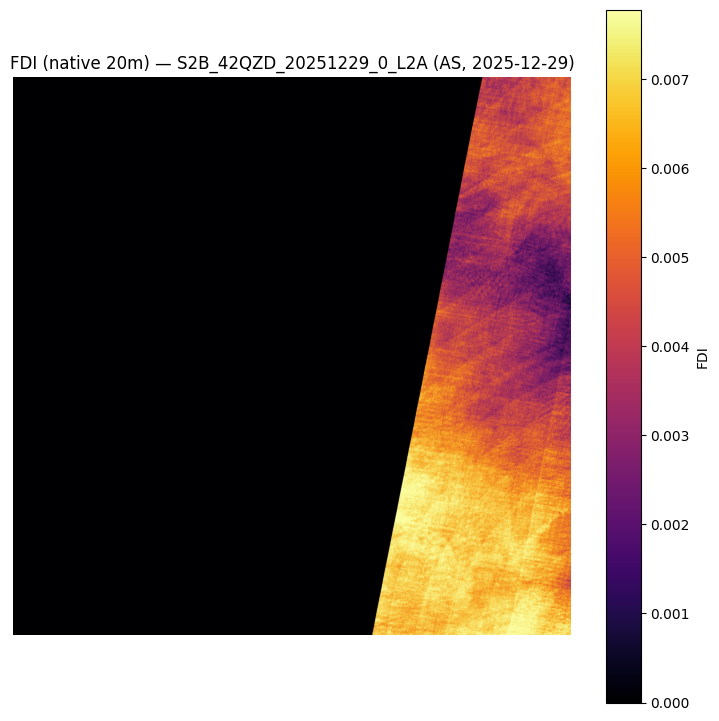

In [8]:
if len(fdi_summary) > 0:
    row = fdi_summary.iloc[0]
    with rasterio.open(row["fdi_tif"]) as src:
        arr = src.read(1)
    vmin, vmax = np.nanpercentile(arr, [2, 98])
    plt.figure(figsize=(9, 9))
    plt.imshow(arr, cmap="inferno", norm=Normalize(vmin=vmin, vmax=vmax))
    plt.colorbar(label="FDI")
    plt.title(f"FDI (native 20m) — {row['tile_id']} ({row['region']}, {row['date']})")
    plt.axis("off")
    plt.show()
else:
    print("No tiles processed — check DATE_RANGE / MAX_CLOUD_COVER in Section 3.")


## 8. Aggregate onto your existing grid (`grid_master_full.csv`)

This cell will check a few likely locations first (including Drive, so it survives
across sessions once placed there). If it isn't found anywhere, it opens Colab's
file picker so you select it directly from your computer — no path-guessing needed.


In [9]:
from google.colab import files

CANDIDATE_PATHS = [
    "/content/grid_master_full.csv",
    "/content/drive/MyDrive/AQUASTRAT/grid_master_full.csv",
    "/content/drive/MyDrive/grid_master_full.csv",
]

GRID_CSV_PATH = next((p for p in CANDIDATE_PATHS if os.path.exists(p)), None)

if GRID_CSV_PATH is None:
    print("grid_master_full.csv not found in the usual locations.")
    print("Select it from your computer in the file picker below:")
    uploaded = files.upload()  # opens a browser file picker
    if uploaded:
        GRID_CSV_PATH = "/content/" + list(uploaded.keys())[0]
    else:
        raise FileNotFoundError(
            "No file was uploaded. Re-run this cell and pick grid_master_full.csv, "
            "or upload it to Drive at /content/drive/MyDrive/AQUASTRAT/grid_master_full.csv "
            "and re-run."
        )

print(f"Using: {GRID_CSV_PATH}")

grid_df = pd.read_csv(GRID_CSV_PATH)
grid_df["fdi_mean"] = np.nan
grid_df["fdi_p95"] = np.nan
grid_df["fdi_max"] = np.nan
grid_df["fdi_n_tiles"] = 0

for region in grid_df["region"].unique():
    region_tiles = fdi_summary[fdi_summary["region"] == region] if len(fdi_summary) else pd.DataFrame()
    if region_tiles.empty:
        continue

    opened = [rasterio.open(p) for p in region_tiles["fdi_tif"]]
    region_mask = grid_df["region"] == region

    for idx in grid_df[region_mask].index:
        lat_min, lat_max = grid_df.at[idx, "lat_min"], grid_df.at[idx, "lat_max"]
        lon_min, lon_max = grid_df.at[idx, "lon_min"], grid_df.at[idx, "lon_max"]

        pixel_vals = []
        for src in opened:
            try:
                left, bottom, right, top = transform_bounds(
                    "EPSG:4326", src.crs, lon_min, lat_min, lon_max, lat_max
                )
            except Exception:
                continue
            win = rasterio.windows.from_bounds(left, bottom, right, top, transform=src.transform)
            win = win.round_offsets().round_lengths()
            if win.width <= 0 or win.height <= 0:
                continue
            try:
                data = src.read(1, window=win)
            except Exception:
                continue
            valid = data[np.isfinite(data)]
            if valid.size > 0:
                pixel_vals.append(valid)

        if pixel_vals:
            allvals = np.concatenate(pixel_vals)
            grid_df.at[idx, "fdi_mean"] = float(np.mean(allvals))
            grid_df.at[idx, "fdi_p95"] = float(np.percentile(allvals, 95))
            grid_df.at[idx, "fdi_max"] = float(np.max(allvals))
            grid_df.at[idx, "fdi_n_tiles"] = len(pixel_vals)

    for src in opened:
        src.close()

    covered = int((grid_df[region_mask]["fdi_n_tiles"] > 0).sum())
    total = region_mask.sum()
    print(f"{region}: {covered} / {total} grid cells received FDI coverage ({100*covered/total:.1f}%)")

grid_df.to_csv(os.path.join(WORK_DIR, "grid_master_full_with_fdi.csv"), index=False)
grid_df[grid_df["fdi_n_tiles"] > 0].head(10)


grid_master_full.csv not found in the usual locations.
Select it from your computer in the file picker below:


Saving grid_master_full.csv to grid_master_full.csv
Using: /content/grid_master_full.csv
AS: 169 / 2272 grid cells received FDI coverage (7.4%)
BOB: 124 / 3349 grid cells received FDI coverage (3.7%)
IO: 13 / 10355 grid cells received FDI coverage (0.1%)


,grid_id,region,lat_min,lat_max,lon_min,lon_max,lat_center,lon_center,is_land,wildlife_count,...,sst,salinity,current_u,current_v,ssh,has_ocean_physics,fdi_mean,fdi_p95,fdi_max,fdi_n_tiles
43,AS_00043,AS,8.000000,8.225225,75.754462,75.981310,8.112613,75.867886,False,0.0,...,29.180490,34.179554,0.100203,-0.048342,0.539379,True,-0.000428,0.000000,0.003440,1
44,AS_00044,AS,8.000000,8.225225,75.981310,76.000000,8.112613,76.094734,False,0.0,...,NaN,NaN,NaN,NaN,NaN,False,0.000000,0.000000,0.000000,1
1468,AS_01607,AS,16.108108,16.333333,71.613318,71.847206,16.220721,71.730262,False,0.0,...,28.997297,35.430950,0.004019,0.046478,0.457404,True,0.000000,0.000000,0.000000,1
1469,AS_01608,AS,16.108108,16.333333,71.847206,72.081094,16.220721,71.964150,False,2.0,...,29.057701,35.359192,-0.021871,0.035006,0.466723,True,0.000000,0.000000,0.000000,1
1470,AS_01609,AS,16.108108,16.333333,72.081094,72.314983,16.220721,72.198039,False,3.0,...,29.071106,35.297668,-0.014377,-0.009456,0.473035,True,0.000000,0.000000,0.000000,1
1471,AS_01610,AS,16.108108,16.333333,72.314983,72.548871,16.220721,72.431927,False,11.0,...,29.100830,35.171566,-0.021628,-0.010407,0.477206,True,0.001956,0.007809,0.069403,1
1472,AS_01611,AS,16.108108,16.333333,72.548871,72.782759,16.220721,72.665815,False,0.0,...,29.136967,34.974453,-0.028177,0.001655,0.483388,True,0.007069,0.008682,0.073153,1
1473,AS_01612,AS,16.108108,16.333333,72.782759,73.016647,16.220721,72.899703,False,0.0,...,29.138510,34.765594,-0.001475,-0.033349,0.488379,True,0.006172,0.007963,0.031029,1
1500,AS_01650,AS,16.333333,16.558559,71.619788,71.853946,16.445946,71.736867,False,0.0,...,28.996803,35.425079,-0.008288,0.066570,0.457788,True,0.000000,0.000000,0.000000,1
1501,AS_01651,AS,16.333333,16.558559,71.853946,72.088104,16.445946,71.971025,False,58.0,...,29.048109,35.349274,-0.014954,0.015540,0.469678,True,0.000000,0.000000,0.000000,1


## 9. Validation — does FDI agree with your CNN/LSTM-derived plastic density?

FDI is a physics-based spectral index, not a trained classifier — there's no
train/test split or labeled ground truth to compute precision/recall/F1 against.
The honest way to validate it here: check whether grid cells your pipeline already
flags as higher plastic density (`predicted_density`, from the LSTM/risk stage —
`ecological_risk_assessment.csv`) also show higher `fdi_mean`.

**Framing for the report**: this is an *internal consistency check between two
independently-derived estimates* (satellite spectral index vs. LSTM-based density
prediction), not a ground-truth accuracy metric — be upfront about that distinction,
it's a legitimate and honest way to validate an unsupervised index.

Upload `ecological_risk_assessment.csv` (from your Objective 4 outputs) below.


In [11]:
DENSITY_CANDIDATE_PATHS = [
    "/content/ecological_risk_assessment.csv",
    "/content/drive/MyDrive/AQUASTRAT/ecological_risk_assessment.csv",
]

DENSITY_CSV_PATH = next((p for p in DENSITY_CANDIDATE_PATHS if os.path.exists(p)), None)

if DENSITY_CSV_PATH is None:
    print("ecological_risk_assessment.csv not found in the usual locations.")
    print("Select it from your computer in the file picker below:")
    uploaded = files.upload()
    if uploaded:
        DENSITY_CSV_PATH = "/content/" + list(uploaded.keys())[0]
    else:
        raise FileNotFoundError("No file uploaded — re-run this cell and pick ecological_risk_assessment.csv.")

print(f"Using: {DENSITY_CSV_PATH}")
density_df = pd.read_csv(DENSITY_CSV_PATH)[["grid_id", "region", "predicted_density"]]

# Join on grid_id, keep only cells where FDI actually has coverage
fdi_cells = grid_df[grid_df["fdi_n_tiles"] > 0][["grid_id", "region", "fdi_mean", "fdi_p95", "fdi_n_tiles"]]
validation_df = fdi_cells.merge(density_df, on=["grid_id", "region"], how="inner")

print(f"\nCells with BOTH FDI coverage and predicted_density: {len(validation_df)}")
validation_df.head(10)


ecological_risk_assessment.csv not found in the usual locations.
Select it from your computer in the file picker below:


Saving ecological_risk_assessment.csv to ecological_risk_assessment.csv
Using: /content/ecological_risk_assessment.csv

Cells with BOTH FDI coverage and predicted_density: 255


,grid_id,region,fdi_mean,fdi_p95,fdi_n_tiles,predicted_density
0,AS_00043,AS,-0.000428,0.000000,1,0.108618
1,AS_00044,AS,0.000000,0.000000,1,0.108524
2,AS_01607,AS,0.000000,0.000000,1,0.106572
3,AS_01608,AS,0.000000,0.000000,1,0.134771
4,AS_01609,AS,0.000000,0.000000,1,0.141274
5,AS_01610,AS,0.001956,0.007809,1,0.158403
6,AS_01611,AS,0.007069,0.008682,1,0.106364
7,AS_01612,AS,0.006172,0.007963,1,0.106290
8,AS_01650,AS,0.000000,0.000000,1,0.106677
9,AS_01651,AS,0.000000,0.000000,1,0.186454


In [12]:
from scipy.stats import spearmanr

if len(validation_df) >= 5:
    rho, pval = spearmanr(validation_df["fdi_mean"], validation_df["predicted_density"])
    print(f"Spearman correlation (fdi_mean vs predicted_density): rho = {rho:.3f}, p = {pval:.4f}")
    if pval < 0.05:
        direction = "positive" if rho > 0 else "negative"
        print(f"-> Statistically significant {direction} association (n={len(validation_df)}).")
    else:
        print(f"-> Not statistically significant at this sample size (n={len(validation_df)}). "
              f"Report this honestly -- a small overlap sample is expected given FDI's "
              f"partial tile coverage; state it as a limitation, not a failure.")
else:
    rho, pval = float("nan"), float("nan")
    print(f"Only {len(validation_df)} overlapping cells -- too few for a meaningful correlation. "
          f"Increase MAX_ITEMS_PER_REGION in Section 3 and re-run to grow FDI coverage, then retry this cell.")


Spearman correlation (fdi_mean vs predicted_density): rho = -0.222, p = 0.0004
-> Statistically significant negative association (n=255).


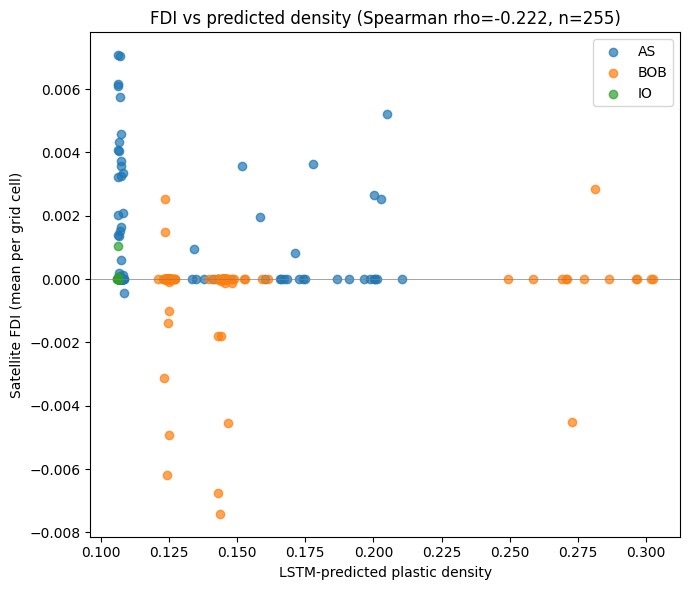

Saved: /content/drive/MyDrive/AQUASTRAT/fdi_stream_outputs/fdi_density_validation.csv


In [13]:
if len(validation_df) >= 5:
    fig, ax = plt.subplots(figsize=(7, 6))
    colors = {"AS": "#1f77b4", "BOB": "#ff7f0e", "IO": "#2ca02c"}
    for region, sub in validation_df.groupby("region"):
        ax.scatter(sub["predicted_density"], sub["fdi_mean"],
                   label=region, alpha=0.7, color=colors.get(region, "gray"))
    ax.set_xlabel("LSTM-predicted plastic density")
    ax.set_ylabel("Satellite FDI (mean per grid cell)")
    ax.set_title(f"FDI vs predicted density (Spearman rho={rho:.3f}, n={len(validation_df)})")
    ax.axhline(0, color="gray", linewidth=0.5)
    ax.legend()
    plt.tight_layout()
    plt.show()

    out_path = os.path.join(WORK_DIR, "fdi_density_validation.csv")
    validation_df.to_csv(out_path, index=False)
    print(f"Saved: {out_path}")


## 10. Notes for the report

- **No resolution compromise vs. the published method.** B06/B11 processed at their
  true native 20m resolution; B08's 10m→20m alignment is the same step the original
  Biermann et al. (2020) method requires to combine the three bands at all — not an
  extra cut we introduced for speed.
- **The earlier slowdown was `reproject()`'s inefficient remote-warp request
  pattern**, not resolution — removing it (this version) is what made it fast, with
  no fidelity tradeoff.
- **RAM crash fix**: unbounded GDAL/VSI caching across many remote file opens
  accumulates memory over the whole session — it wasn't IO-specific, IO just
  happened to be next in line when the ceiling was hit. Fixed by bounding
  `GDAL_CACHEMAX`, disabling `VSI_CACHE`, and forcing `gc.collect()` after every tile.
- **Crash-safe now**: results are written to Google Drive incrementally, one tile at
  a time, and re-running the cell resumes automatically from wherever it stopped —
  a future crash costs at most the one tile in progress, not the whole session.
- **Validation is a consistency check, not ground-truth accuracy** — FDI is a fixed
  physics formula, not a trained model, so precision/recall/F1 don't apply. Report
  the Spearman correlation from Section 9 and its p-value honestly, including if it's
  weak or not significant — that's still a legitimate, defensible result to report,
  especially given the small overlap sample size from a capped tile budget.
- Report tile count, cloud-cover range, per-tile timing, and grid coverage % using
  the actual numbers this run prints (Sections 4, 6, 8) — don't use placeholders.
- Still a representative sample of tiles per region, not full regional coverage —
  state that plainly.
- Complementary coarse satellite screening layer, not fused into the trained CNN.
